In [4]:
# TASK 1: EDA on Superstore Retail Sales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('superstore_sales (1).csv')
print(df.shape)
df.head()

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [5]:
# Check Data Quality
print("---INFO---")
df.info()

---INFO---
<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quanti

In [6]:
print("|n---NULL VALUES---")
print(df.isnull().sum())

|n---NULL VALUES---
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [8]:
print("\n---DUPLICATES---")
print("Duplicate rows:", df.duplicated().sum())


---DUPLICATES---
Duplicate rows: 504


In [10]:
# cleaning
print("Before cleaning:", df.shape)

# Drop rows where Order date is missing
df = df.dropna(subset=['Order Date'])

# Drop duplicate rows
df = df.drop_duplicates()

Before cleaning: (9994, 21)


In [11]:
# cleaning - dates + new columns
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Profit Margin'] = df['Profit'] / df['Sales']

print("After cleaning:", df.shape)
print(df[['Order Date', 'Ship Date', 'Year', 'Month', 'Profit Margin']].head())

After cleaning: (9994, 24)
  Order Date  Ship Date  Year  Month  Profit Margin
0 2017-11-08 2017-11-11  2017     11         0.1600
1 2017-11-08 2017-11-11  2017     11         0.3000
2 2017-06-12 2017-06-16  2017      6         0.4700
3 2016-10-11 2016-10-18  2016     10        -0.4000
4 2016-10-11 2016-10-18  2016     10         0.1125


In [12]:
# Numbers
print("Total Sales:", round(df['Sales'].sum(), 2))
print("Total Profit:", round(df['Profit'].sum(), 2))
print("\nSales by category:")
print(df.groupby('Category')['Sales'].sum().round(2))
print("\nProfit by Category:")
print(df.groupby('Category')['Profit'].sum().round(2))

Total Sales: 2297200.86
Total Profit: 286397.02

Sales by category:
Category
Furniture          741999.80
Office Supplies    719047.03
Technology         836154.03
Name: Sales, dtype: float64

Profit by Category:
Category
Furniture           18451.27
Office Supplies    122490.80
Technology         145454.95
Name: Profit, dtype: float64


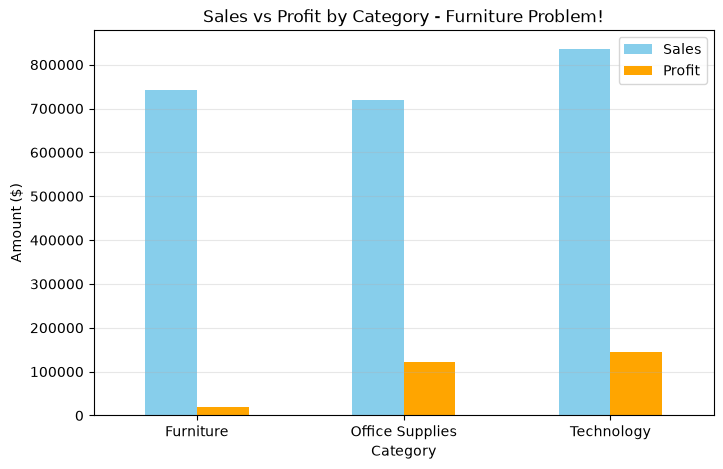

In [13]:
# Charts - Sales vs Profit by Category
import matplotlib.pyplot as plt

cat = df.groupby('Category')[['Sales', 'Profit']].sum()

cat.plot(kind='bar', figsize=(8,5), color=['skyblue', 'orange'])
plt.title('Sales vs Profit by Category - Furniture Problem!')
plt.ylabel('Amount ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

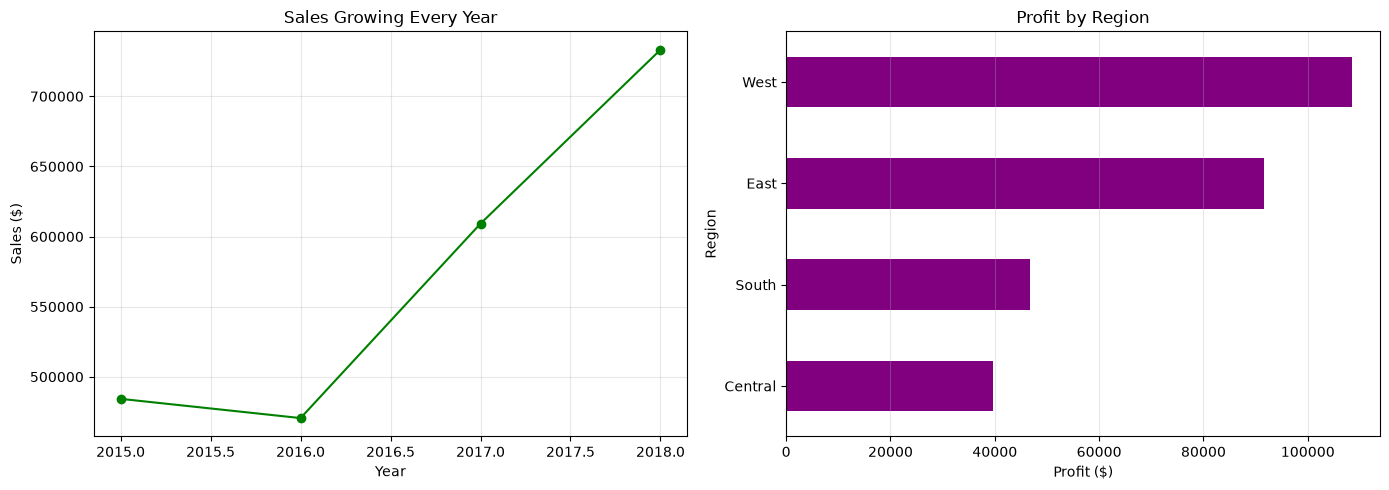

In [14]:
# Charts - Yearly Trend + Profit by Region
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# chart 1 - Yearly Sales Trend
df.groupby('Year')['Sales'].sum().plot(kind='line', marker='o', ax=axes[0], color='green')
axes[0].set_title('Sales Growing Every Year')
axes[0].set_ylabel('Sales ($)')
axes[0].grid(alpha=0.3)

# chart 2 -  Profit by Region
df.groupby('Region')['Profit'].sum().sort_values().plot(kind='barh', ax=axes[1], color='purple')
axes[0].set_title('Sales Growing Every Year')
axes[1].set_title('Profit by Region')
axes[1].set_xlabel('Profit ($)')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

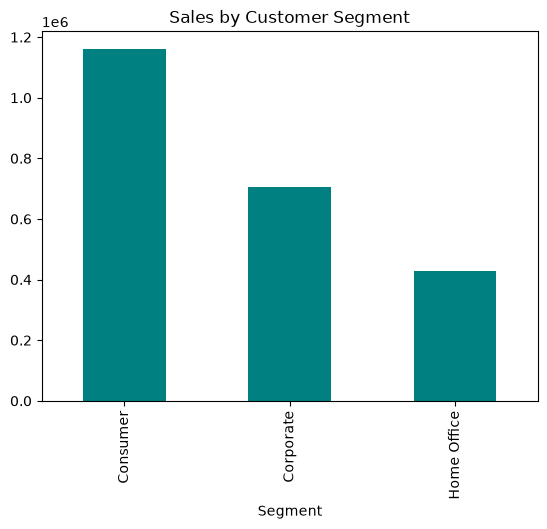

In [16]:
# Segment Chart
df.groupby('Segment')['Sales'].sum().plot(kind='bar', color='teal')
plt.title('Sales by Customer Segment')
plt.show()

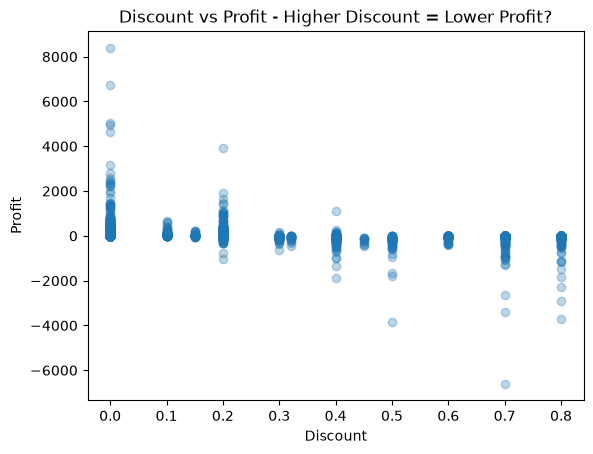

In [19]:
# Discount vs Profit scatter
plt.scatter(df['Discount'], df['Profit'], alpha=0.3)
plt.title('Discount vs Profit - Higher Discount = Lower Profit?')
plt.xlabel('Discount'); plt.ylabel('Profit')
plt.show()

## Conclusion - Key Findings

1. **Total Sales:** $2,297,200 | **Total Profit:** $286,397 after cleaning 9,994 rows
2. **Furniture Problem:** Highest Sales $741,999 but Lowest Profit only $18,451. Furniture is selling but not making money - need to check pricing / discount.
3. **Best Category:** Technology - Sales $836,154 and Profit $145,454
4. **Growth:** Sales growing every year - 2015 to 2018, highest in 2018
5. **Best Region:** West ($108k profit) | **Weakest Region:** Central ($40k profit)
6. **Recommendation:** Focus on Technology, fix Furniture pricing, improve Central region sales.
7. **Segment:** Consumer is biggest segment (~1.17M sales), followed by Corporate and Home Office.
8. **Discount Effect:** At 0% discount profit up to $8000. At 70-80% discount profit goes negative. Reduce high discounts.

 **Cleaning Done:** Removed 806 empty rows, removed duplicates, converted Order Date / Ship Date to date format, created Year, Month, Profit Margin columns.
  